<a href="https://colab.research.google.com/github/mrdbourke/pytorch-deep-learning/blob/main/extras/exercises/03_pytorch_computer_vision_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03. PyTorch Computer Vision Exercises

The following is a collection of exercises based on computer vision fundamentals in PyTorch.

They're a bunch of fun.

You're going to get to write plenty of code!

## Resources

1. These exercises are based on [notebook 03 of the Learn PyTorch for Deep Learning course](https://www.learnpytorch.io/03_pytorch_computer_vision/). 
2. See a live [walkthrough of the solutions (errors and all) on YouTube](https://youtu.be/_PibmqpEyhA). 
  * **Note:** Going through these exercises took me just over 3 hours of solid coding, so you should expect around the same.
3. See [other solutions on the course GitHub](https://github.com/mrdbourke/pytorch-deep-learning/tree/main/extras/solutions).

In [1]:
# Check for GPU
!nvidia-smi

Fri Jul  3 20:02:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.97                 Driver Version: 595.97         CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4060 ...  WDDM  |   00000000:01:00.0  On |                  N/A |
| N/A   61C    P8              5W /  124W |    1448MiB /   8188MiB |     36%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Import torch
import torch

# Exercises require PyTorch > 1.10.0
print(torch.__version__)

# TODO: Setup device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"


2.12.0+cu126


## 1. What are 3 areas in industry where computer vision is currently being used?

1. Self-driving car
2. Disease detection
3. Security(like detceting the one invading your house)

## 2. Search "what is overfitting in machine learning" and write down a sentence about what you find. 

Overfitting means the model learns too much from the training data, including noises and outliers.

It performs very well on training data, but poorly on testing data

## 3. Search "ways to prevent overfitting in machine learning", write down 3 of the things you find and a sentence about each. 
> **Note:** there are lots of these, so don't worry too much about all of them, just pick 3 and start with those.

1. Reduce model complexity
2. use regulization(L1/L2)
3. apply dropout

## 4. Spend 20-minutes reading and clicking through the [CNN Explainer website](https://poloclub.github.io/cnn-explainer/).

* Upload your own example image using the "upload" button on the website and see what happens in each layer of a CNN as your image passes through it.

## 5. Load the [`torchvision.datasets.MNIST()`](https://pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html#torchvision.datasets.MNIST) train and test datasets.

In [3]:
import torchvision
from torchvision.transforms import ToTensor
from torchvision import datasets

train_data = datasets.MNIST(root="data", train=True, transform=ToTensor(), target_transform=None, download=True)
test_data = datasets.MNIST(root="data", train=False, transform=ToTensor(), target_transform=None, download=True)
len(train_data), len(test_data)

(60000, 10000)

In [4]:
train_data

Dataset MNIST
    Number of datapoints: 60000
    Root location: data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [5]:
X, y = train_data[0]
X.shape, y

(torch.Size([1, 28, 28]), 5)

In [6]:
class_names = train_data.classes

## 6. Visualize at least 5 different samples of the MNIST training dataset.

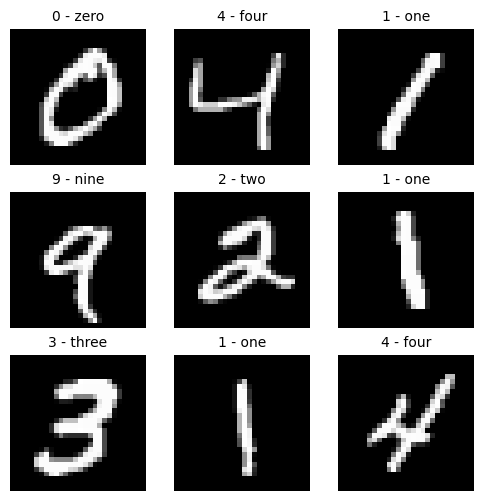

In [7]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 6))
rows, cols = 3, 3
for i in range(1, rows * cols + 1):
    plt.subplot(rows, cols, i)
    X, y = train_data[i]
    plt.imshow(X.squeeze(), cmap='gray')
    plt.title(class_names[y], fontsize=10)
    plt.axis(False)

## 7. Turn the MNIST train and test datasets into dataloaders using `torch.utils.data.DataLoader`, set the `batch_size=32`.

In [ ]:
from torch.utils.data import DataLoader
BATCH_SIZE = 32

train_dataloader = DataLoader(dataset=train_data,
                              batch_size=BATCH_SIZE,
                              shuffle=True)
test_dataloader = DataLoader(dataset=test_data,
                              batch_size=BATCH_SIZE,
                              shuffle=False) # test data 不应该shuffle
train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x231dce3f3b0>,
 <torch.utils.data.dataloader.DataLoader at 0x231da819220>)

## 8. Recreate `model_2` used in notebook 03 (the same model from the [CNN Explainer website](https://poloclub.github.io/cnn-explainer/), also known as TinyVGG) capable of fitting on the MNIST dataset.

In [9]:
from torch import nn
class MNISTModel(nn.Module):
    def __init__(self, input_shape, hidden_units, output_shape):
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1
            ),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1
            ),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units*7*7, out_features=output_shape)
        )
    
    def forward(self, x:torch.Tensor) -> torch.Tensor:
        return self.classifier(self.conv_block_2(self.conv_block_1(x)))

# model = MNISTModel(1, 10, len(class_names))
# model

## 9. Train the model you built in exercise 8. for 5 epochs on CPU and GPU and see how long it takes on each.

In [10]:
len(class_names)

10

In [11]:
model_cpu = MNISTModel(1, 10, len(class_names))

model_cuda = MNISTModel(1, 10, len(class_names)).to(device)

loss_fn = nn.CrossEntropyLoss()
optim_cpu = torch.optim.Adam(params=model_cpu.parameters(), lr=0.01)
optim_cuda = torch.optim.Adam(params=model_cuda.parameters(), lr=0.01)

from helper_functions import accuracy_fn
from tqdm.auto import trange, tqdm
from timeit import default_timer as timer

In [12]:
def train_step(model: nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: nn.Module,
               optimizer: torch.optim.Optimizer,
               acc_fn = accuracy_fn,
               device: str = device) -> None:
    model.train()
    train_loss, train_acc = 0, 0
    for X, y in dataloader:
        X, y = X.to(device), y.to(device)
        pred_logits = model(X)
        
        loss = loss_fn(pred_logits, y)
        train_loss += loss
        train_acc += acc_fn(y, pred_logits.argmax(dim=1))
        
        optimizer.zero_grad()
        
        loss.backward()
        
        optimizer.step()
    train_loss /= len(dataloader)
    train_acc /= len(dataloader)
    print(f"Train loss: {train_loss:.5f}, Train Acc: {train_acc:.2f}%")

In [13]:
def test_step(model: torch.nn.Module,
          dataloader: torch.utils.data.DataLoader,
          loss_fn: nn.Module,
          acc_fn=accuracy_fn,
          device: str=device):
    test_loss, test_acc =0, 0
    model.eval()
    with torch.inference_mode():
        for X_test, y_test in dataloader:
            X_test, y_test = X_test.to(device), y_test.to(device)
            # 1. forward pass
            test_logits = model(X_test)
            # 2. calculate loss
            test_loss += loss_fn(test_logits, y_test)
            test_acc += acc_fn(y_test, test_logits.argmax(dim=1))
        
        test_loss /= len(dataloader)
        test_acc /= len(dataloader)
    
    # print
    print(f"Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%\n")

In [14]:
epochs = 3
cpu_start = timer()

for epoch in tqdm(range(epochs), desc="training..."):
    train_step(model_cpu, train_dataloader, loss_fn, optim_cpu, accuracy_fn, "cpu")
    test_step(model_cpu, test_dataloader, loss_fn, accuracy_fn, "cpu")
    
cpu_end = timer()
cpu_total = cpu_end - cpu_start
cpu_total

training...:   0%|          | 0/3 [00:00<?, ?it/s]

Train loss: 0.20671, Train Acc: 93.71%
Test loss: 0.12186, Test acc: 96.28%

Train loss: 0.11454, Train Acc: 96.66%
Test loss: 0.12302, Test acc: 96.38%

Train loss: 0.10400, Train Acc: 96.91%
Test loss: 0.09171, Test acc: 97.15%



138.41621140000643

In [15]:
epochs = 3
gpu_start = timer()

for epoch in tqdm(range(epochs), desc="training..."):
    train_step(model_cuda, test_dataloader, loss_fn, optim_cuda, accuracy_fn, device)
    test_step(model_cuda, test_dataloader, loss_fn, accuracy_fn, device)
    
gpu_end = timer()
gpu_total = gpu_end - gpu_start
gpu_total

training...:   0%|          | 0/3 [00:00<?, ?it/s]

Train loss: 0.38028, Train Acc: 87.45%
Test loss: 0.13069, Test acc: 95.34%

Train loss: 0.11884, Train Acc: 96.03%
Test loss: 0.09741, Test acc: 96.62%

Train loss: 0.09904, Train Acc: 96.83%
Test loss: 0.05614, Test acc: 98.27%



13.69975940004224

## 10. Make predictions using your trained model and visualize at least 5 of them comparing the prediciton to the target label.

In [28]:
def make_predictions(model: nn.Module, data: list, device: 'str') -> torch.Tensor:
    model = model.to(device)
    model.eval()
    pred_probs = []
    with torch.inference_mode():
        for sample in data:
            sample = sample.to(device)
            pred_logit = model(sample.unsqueeze(dim=0))
            pred_prob = torch.softmax(pred_logit.squeeze(), dim=0)
            pred_probs.append(pred_prob.cpu())
    return torch.stack(pred_probs)

In [26]:
import random

test_samples = []
test_labels = []

for sample, label in random.sample(list(test_data), k=6):
    test_samples.append(sample)
    test_labels.append(label)

In [29]:
test_pred_probs = make_predictions(model_cuda, test_samples, device)
test_preds = test_pred_probs.argmax(dim=1)

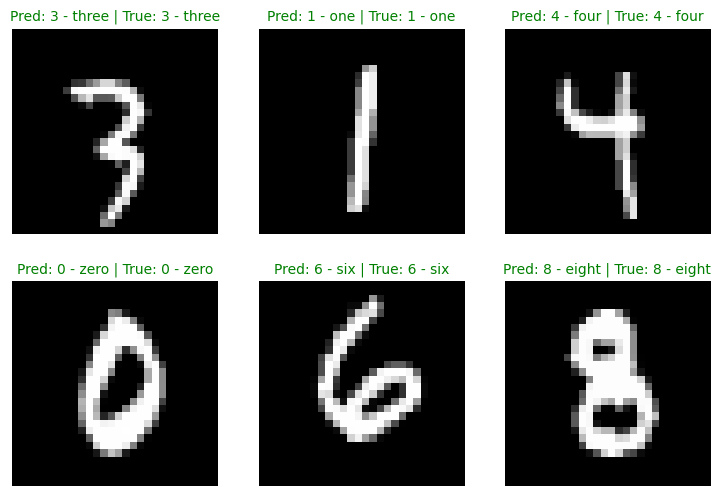

In [30]:
plt.figure(figsize=(9, 6))
rows = 2
cols = 3

for i, sample in enumerate(test_samples):
    plt.subplot(rows, cols, i+1)
    plt.imshow(sample.squeeze(), cmap='grey')
    pred_label = class_names[test_preds[i]]
    true_label = class_names[test_labels[i]]
    color = 'g' if (pred_label == true_label) else 'r'
    plt.title(f"Pred: {pred_label} | True: {true_label}", fontsize=10, c=color)
    plt.axis(False)

## 11. Plot a confusion matrix comparing your model's predictions to the truth labels.

In [41]:
# get all predictions
model_cuda.eval()
labels = []
preds = []
with torch.inference_mode():
    for X, y in tqdm(test_dataloader):
        X, y = X.to(device), y.to(device)
        pred_logit = model_cuda(X)
        pred_label = torch.softmax(pred_logit.squeeze(), dim=0).argmax(dim=1)
        preds.append(pred_label.cpu())
        labels.append(y.cpu())
preds_tensor = torch.cat(preds)
labels_tensor = torch.cat(labels)
preds_tensor, labels_tensor

  0%|          | 0/313 [00:00<?, ?it/s]

(tensor([4, 5, 8,  ..., 2, 7, 3]), tensor([4, 5, 8,  ..., 2, 7, 3]))

In [ ]:
import torchmetrics
import mlxtend
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

confmat = ConfusionMatrix(task="multiclass", num_classes=len(class_names))
confmat_tensor = confmat(preds_tensor, labels_tensor)
confmat_tensor

tensor([[ 905,    1,   12,    0,    6,    8,   17,    1,   28,    2],
        [   0, 1089,    5,    0,    8,    9,    1,    5,   15,    3],
        [   9,   18,  861,   37,   10,    3,    4,   23,   58,    9],
        [   6,    2,   12,  910,    0,   23,    0,    3,   26,   28],
        [   3,    6,    1,    5,  854,    8,   11,    6,   21,   67],
        [   4,    1,    2,   43,    3,  770,   11,    0,   42,   16],
        [  22,   10,    5,    3,   17,   58,  819,    1,   19,    4],
        [   9,   11,   35,   29,    6,   10,    0,  775,   33,  120],
        [   7,    4,    6,    7,    1,   12,    7,    2,  925,    3],
        [   4,    3,    2,    0,   18,   12,    0,   12,   30,  928]])

(<Figure size 1000x700 with 1 Axes>,
 <Axes: xlabel='predicted label', ylabel='true label'>)

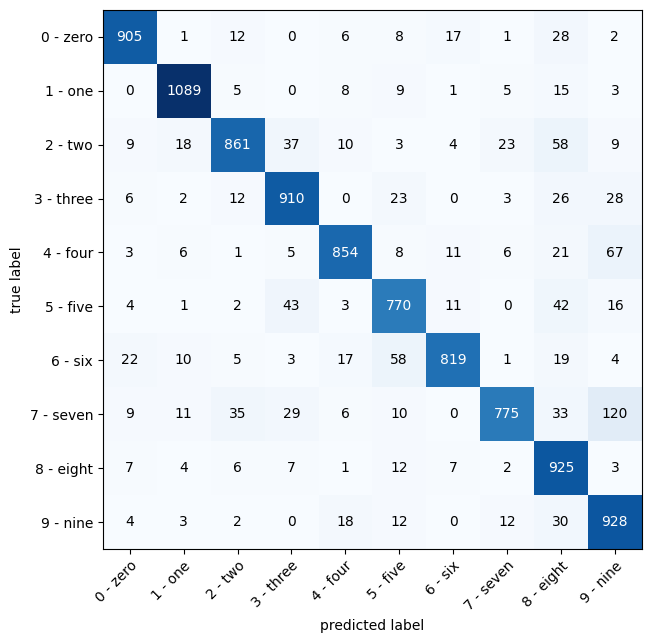

In [43]:
plot_confusion_matrix(conf_mat= confmat_tensor.numpy(),
                      figsize=(10, 7),
                      class_names=class_names)

## 12. Create a random tensor of shape `[1, 3, 64, 64]` and pass it through a `nn.Conv2d()` layer with various hyperparameter settings (these can be any settings you choose), what do you notice if the `kernel_size` parameter goes up and down?

In [44]:
ran_tensor = torch.randn(1, 3, 64, 64)
conv_k3 = nn.Conv2d(in_channels=3, out_channels=10, kernel_size=3, stride=1, padding=1)
out_k3 = conv_k3(ran_tensor)
conv_k5 = nn.Conv2d(in_channels=3, out_channels=10, kernel_size=5, stride=1, padding=1)
out_k5 = conv_k5(ran_tensor)
conv_k7 = nn.Conv2d(in_channels=3, out_channels=10, kernel_size=7, stride=1, padding=1)
out_k7 = conv_k7(ran_tensor)
out_k3.shape, out_k5.shape, out_k7.shape

(torch.Size([1, 10, 64, 64]),
 torch.Size([1, 10, 62, 62]),
 torch.Size([1, 10, 60, 60]))

the bigger the kernel size, the smaller the output tensor size is

## 13. Use a model similar to the trained `model_2` from notebook 03 to make predictions on the test [`torchvision.datasets.FashionMNIST`](https://pytorch.org/vision/main/generated/torchvision.datasets.FashionMNIST.html) dataset. 
* Then plot some predictions where the model was wrong alongside what the label of the image should've been. 
* After visualing these predictions do you think it's more of a modelling error or a data error? 
* As in, could the model do better or are the labels of the data too close to each other (e.g. a "Shirt" label is too close to "T-shirt/top")?

In [46]:
fashion_mnist_train = datasets.FashionMNIST(root="data",
                                            download=True,
                                            train=True,
                                            transform=ToTensor())

fashion_mnist_test = datasets.FashionMNIST(root="data",
                                           train=False,
                                           download=True,
                                           transform=ToTensor())

len(fashion_mnist_train), len(fashion_mnist_test)

(60000, 10000)

In [49]:
class_names = fashion_mnist_train.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [50]:
fashion_train_dataloader = DataLoader(dataset=fashion_mnist_train, batch_size=BATCH_SIZE, shuffle=True)
fashion_test_dataloader = DataLoader(dataset=fashion_mnist_test, batch_size=BATCH_SIZE, shuffle=False)

In [54]:
# 使用的CNN archetecture: Tiny VGG
class FashionMNISTModel(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int) -> None:
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape, out_channels=hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units*7*7, out_features=output_shape),
        )
    def forward(self, x):
        return self.classifier(self.conv_block_2(self.conv_block_1(x)))

In [61]:
model = FashionMNISTModel(1, 16, len(class_names)).to(device)

In [62]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model.parameters(), lr=0.001)

In [63]:
epochs = 3
for epoch in trange(epochs):
    print(f"Epoch: {epoch}\n----------")
    train_step(model, fashion_train_dataloader, loss_fn, optimizer, accuracy_fn, device)
    test_step(model, fashion_test_dataloader, loss_fn, accuracy_fn, device)

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
----------
Train loss: 0.48431, Train Acc: 82.69%
Test loss: 0.37166, Test acc: 86.89%

Epoch: 1
----------
Train loss: 0.31230, Train Acc: 88.79%
Test loss: 0.31446, Test acc: 88.99%

Epoch: 2
----------
Train loss: 0.27606, Train Acc: 89.95%
Test loss: 0.30813, Test acc: 88.99%



In [65]:
y_preds = []
model.eval()
with torch.inference_mode():
    for X, y in tqdm(fashion_test_dataloader):
        X, y = X.to(device), y.to(device)
        y_pred = model(X)
        pred_label = y_pred.argmax(dim=1)
        y_preds.append(pred_label.cpu())
pred_labels = torch.cat(y_preds)
pred_labels, fashion_mnist_test.targets

  0%|          | 0/313 [00:00<?, ?it/s]

(tensor([9, 2, 1,  ..., 8, 1, 8]), tensor([9, 2, 1,  ..., 8, 1, 5]))

In [66]:
torch.sum(pred_labels != fashion_mnist_test.targets)

tensor(1102)

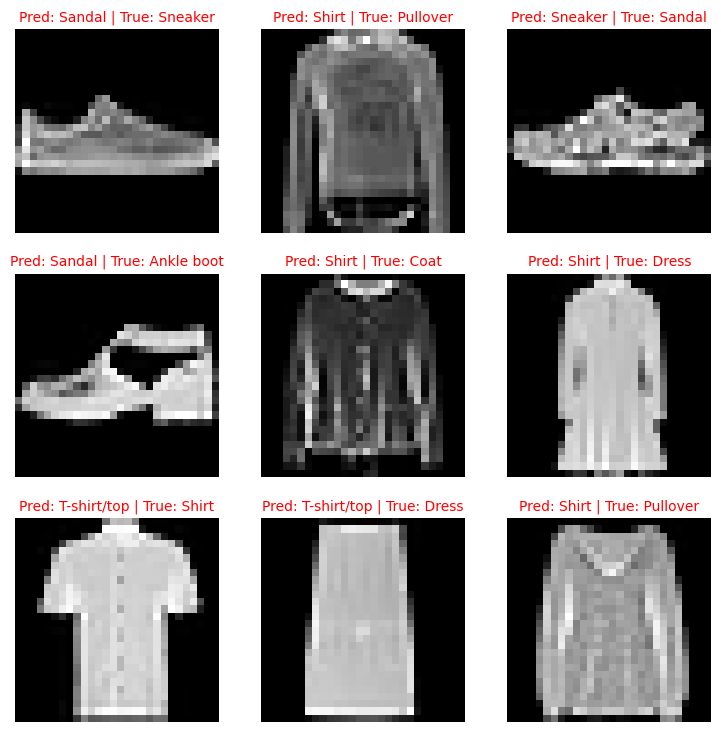

In [74]:
plt.figure(figsize=(9, 9))
rows, cols = 3, 3
wrong_cnt = 0
for i, (sample, label) in enumerate(fashion_mnist_test):
    pred_label = class_names[pred_labels[i]]
    true_label = class_names[label]
    if pred_label == true_label:
        continue
    else:
        wrong_cnt += 1
    
    plt.subplot(rows, cols, wrong_cnt)
    plt.imshow(sample.squeeze(), cmap='grey')
    
    # set title
    title_text = f"Pred: {pred_label} | True: {true_label}"
    plt.title(title_text, fontsize=10, c='r')
    plt.axis(False)
    
    if wrong_cnt >= rows*cols:
        break

More of a data problem instead of model problem